In [42]:
import pandas as pd
import matplotlib.pyplot as plt
orders=pd.read_csv("D:\Cricket score Analysis\orders.csv")
products=pd.read_csv("D:\Cricket score Analysis\products.csv")
customers=pd.read_csv("D:\Cricket score Analysis\customers.csv")

In [7]:

orders.info()
products.info()
orders.head()
products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        50000 non-null  object 
 1   OrderDate      50000 non-null  object 
 2   CustomerID     50000 non-null  object 
 3   ProductID      50000 non-null  object 
 4   Quantity       50000 non-null  int64  
 5   DiscountPct    50000 non-null  float64
 6   PaymentMethod  50000 non-null  object 
 7   OrderStatus    50000 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 3.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ProductID     150 non-null    object
 1   ProductName   150 non-null    object
 2   Category      150 non-null    object
 3   SubCategory   150 non-null    object
 4   CostPrice     150 non-null   

,ProductID,ProductName,Category,SubCategory,CostPrice,SellingPrice
0,PROD0001,Item_Laptops_1,Electronics,Laptops,15000,21011
1,PROD0002,Item_Laptops_2,Electronics,Laptops,2500,3600
2,PROD0003,Item_Supplements_3,Beauty & Health,Supplements,1200,1965
3,PROD0004,Item_Home Decor_4,Home & Kitchen,Home Decor,500,785
4,PROD0005,Item_Appliances_5,Home & Kitchen,Appliances,2500,3253


In [43]:
merged=orders.merge(products,on='ProductID',how='left').merge(customers,on='CustomerID',how='left')
merged['Total_sales']=merged['Quantity']*merged['SellingPrice']*(1-merged['DiscountPct'])
merged.head()
overall_sales=merged['Total_sales'].sum()
print(overall_sales)

1198179777.65


In [17]:
category_sales=merged.groupby("Category")['Total_sales'].sum()
category_sales=(category_sales/ 10**7).round(2)
category_sales.head()

Category
Beauty & Health    31.98
Electronics        26.40
Fashion            36.61
Home & Kitchen     24.83
Name: Total_sales, dtype: float64

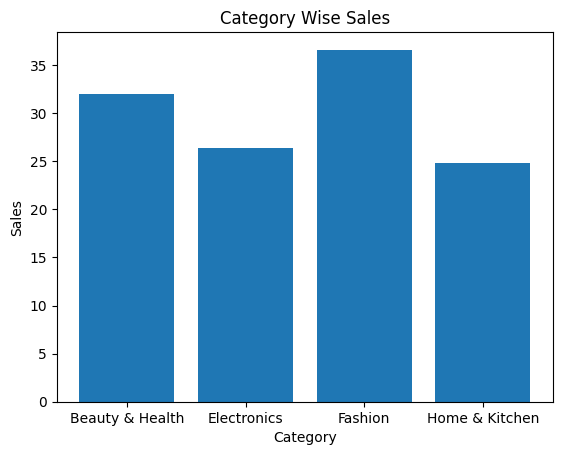

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [27]:
plt.bar(category_sales.index,category_sales.values)
plt.title("Category Wise Sales")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()
plt.savefig("barchart")
plt.Figure()



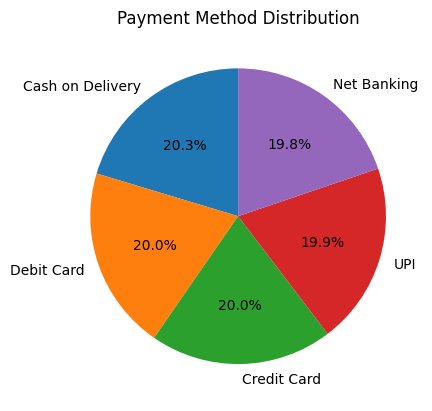

In [25]:
payment_count=merged['PaymentMethod'].value_counts()
plt.pie(payment_count.values,labels=payment_count.index,autopct="%1.1f%%",startangle=90)
plt.title("Payment Method Distribution")
plt.ylabel(" ")
plt.savefig("Piechart")

In [33]:
merged['OrderDate']=pd.to_datetime(merged['OrderDate'])
monthly_sales=merged.groupby(merged['OrderDate'].dt.to_period('M'))['Total_sales'].sum()
monthly_sales.head()

OrderDate
2023-01    47990489.60
2023-02    46265199.55
2023-03    49199387.75
2023-04    51904718.25
2023-05    50018738.05
Freq: M, Name: Total_sales, dtype: float64

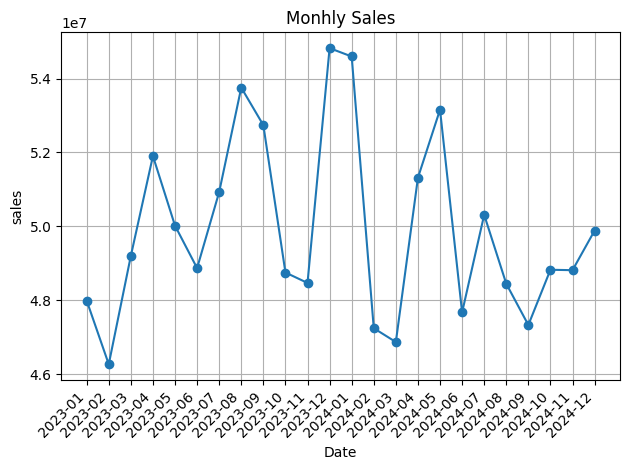

<Figure size 640x480 with 0 Axes>

In [41]:
plt.plot(monthly_sales.index.astype('str'),monthly_sales.values,marker='o')
plt.grid()
plt.xticks(rotation=45,ha='right')
plt.title('Monhly Sales')
plt.xlabel("Date")
plt.ylabel("sales")
plt.tight_layout()
plt.show()
plt.savefig("lineplot")

In [ ]:
merged.head()
top_state=merged.groupby('State')['OrderID'].count()
top_state=top_state.sort_values(ascending=False).head(5)


State
Maharashtra      10482
Uttar Pradesh     5266
West Bengal       4989
Rajasthan         4987
Karnataka         4950
Name: OrderID, dtype: int64

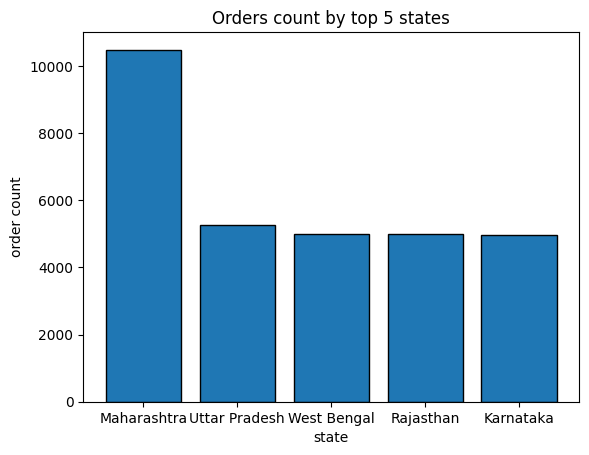

<Figure size 640x480 with 0 Axes>

In [54]:
plt.bar(top_state.index,top_state.values,edgecolor='black')
plt.title("Orders count by top 5 states")
plt.xlabel('state')
plt.ylabel('order count')
plt.show()
plt.savefig("bars")